In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

En esta semana contruiremos la variable objetivo. (Y), es decir que vamos a intentar predecir: es decir, que  trataremos de ver el futuro, la volatilidad que ocurriria despues del dia t

In [2]:
ruta_processed = Path("data/processed")
archivo_features = ( ruta_processed / "SPY_2015_2025_features.csv" ) # establecemos el archivo  de entrada
archivo_targets = ( ruta_processed / "SPY_2015_2025_targets.csv") # establecemos el archivo de salida

In [3]:
if not archivo_features.exists():
     raise FileNotFoundError(f"No se encontro el archivo: {archivo_features}")
# Verificamos que el archivo exista en la computadora

In [4]:
datos_features = pd.read_csv(archivo_features, #leemos el archivo e indexamos la primera columna, que son las fechas
index_col=0,parse_dates=True) #parse asegura que la fechas se interpreten como objeto temporales de tipo fecha
datos = datos_features.copy(deep=True) # se crea una dtaframe sobre ellas sin modificar el archivo base

In [5]:
print(datos.shape)
print(datos.index.min())
print(datos.index.max())
print(datos.columns.tolist())
datos.head()
#hacemos pruebas para verificar los datos

(2765, 40)
2015-01-05 00:00:00
2025-12-31 00:00:00
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Return', 'Abs_Return', 'Sq_Return', 'Vol_5', 'Vol_10', 'Vol_20', 'Vol_30', 'Return_Lag_1', 'Return_Lag_2', 'Return_Lag_5', 'Return_Lag_10', 'Abs_Return_Lag_1', 'Abs_Return_Lag_2', 'Abs_Return_Lag_5', 'Abs_Return_Lag_10', 'Sq_Return_Lag_1', 'Sq_Return_Lag_2', 'Sq_Return_Lag_5', 'Sq_Return_Lag_10', 'Vol_5_Lag_1', 'Vol_10_Lag_1', 'Vol_20_Lag_1', 'Vol_30_Lag_1', 'Mean_Return_5', 'Mean_Return_10', 'Mean_Return_20', 'Mean_Abs_Return_5', 'Mean_Abs_Return_10', 'Mean_Abs_Return_20', 'Momentum_5', 'Momentum_20', 'Volume_Change', 'Range_HL', 'Ratio_Vol_5_30']


,Open,High,Low,Close,Adj Close,Volume,Return,Abs_Return,Sq_Return,Vol_5,...,Mean_Return_10,Mean_Return_20,Mean_Abs_Return_5,Mean_Abs_Return_10,Mean_Abs_Return_20,Momentum_5,Momentum_20,Volume_Change,Range_HL,Ratio_Vol_5_30
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,204.169998,204.369995,201.350006,201.720001,166.623337,169632600,-0.018225,0.018225,0.000332,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.014971,NaN
2015-01-06,202.089996,202.720001,198.860001,199.820007,165.053909,209151400,-0.009464,0.009464,0.000090,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.232967,0.019317,NaN
2015-01-07,201.419998,202.720001,200.880005,202.309998,167.110703,125346700,0.012384,0.012384,0.000153,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.400689,0.009095,NaN
2015-01-08,204.009995,206.160004,203.990005,205.899994,170.076080,147217800,0.017589,0.017589,0.000309,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.174485,0.010539,NaN
2015-01-09,206.399994,206.419998,203.509995,204.250000,168.713120,158567300,-0.008046,0.008046,0.000065,0.015351,...,NaN,NaN,0.013142,NaN,NaN,NaN,NaN,0.077093,0.014247,NaN


In [6]:
columnas_necesarias = [
"Return",
"Vol_5",
"Vol_10",
"Vol_20",
"Vol_30",
"Return_Lag_1",
"Mean_Abs_Return_20",
"Momentum_20",
"Range_HL",
"Ratio_Vol_5_30"]
# definimos una lista con los nombres de las columnas indispensables para las comparaciones posteriores
faltantes = [col for col in columnas_necesarias if col not in datos.columns]
#mediante una compresion de lista se revisa que si algunas de ellas no esta en el Df la instruccion se detenga el codigo y marque el error
assert len(faltantes) == 0, (f"Faltan columnas: {faltantes}")


In [7]:
assert datos.index.is_monotonic_increasing
#comprobamos que el indice de fechas este ordenado de forma ascendente cronologicamente
assert datos.index.is_unique
# verifica que la columna no existan fechas duplicadas

In [8]:
assert not datos["Return"].isna().any()
#verifica que la columnas de rendimientos (return) no tenga ningun valor faltante
assert np.isfinite(datos["Return"]).all()
#verifica que no tenga valores infinitos , debido que luego hay huecos en blanco en los rendimientos
#rompiendo el calculo de ventanas moviles de forma consecutiva

In [17]:
#creamos la lista de horizontes
horizontes=[5,10,20]

In [18]:
for h in horizontes:
#cada horizonte h se toma la columna return y se aplica rolling para abrir una ventana de tamaño h, se calcula su desviacion estandar muestral
        datos[f"Target_Vol_{h}"] = (datos["Return"].rolling(window=h).std(ddof=1).shift(-h)) # con (shift -h) se desplaza todos los resultados obtenidos h posiciones hacia arriba(pasado)
# los resultados se almacenan en columnas creada (target_vol_5, target_vol_10,etc)

In [20]:
i = 100 #fila de prueba con el indice inferior
h = 5 #selecionamos el horizonte
ventana_futura = (datos["Return"].iloc[i + 1:i + h + 1])
#extraemos de forma manual y directa los rendimientos futuros
objetivo_manual = ventana_futura.std(ddof=1)
#calcula a mano la desviacion estandar de esos 5 elemtnos
objetivo_python = datos["Target_Vol_5"].iloc[i]
#extrae el valor que genero automaticamente python en la columna target_vol5 en esa misma fila
print("Fecha t:", datos.index[i])
print("Fechas futuras:")
print(ventana_futura.index)
print("Manual:", objetivo_manual)
print("Python:", objetivo_python)

assert len(ventana_futura) == h
assert np.isclose(objetivo_manual,objetivo_python) # np.isclose comprueba que ambos sean identicos

Fecha t: 2015-05-29 00:00:00
Fechas futuras:
DatetimeIndex(['2015-06-01', '2015-06-02', '2015-06-03', '2015-06-04',
               '2015-06-05'],
              dtype='datetime64[us]', name='Date', freq=None)
Manual: 0.00443138702617891
Python: 0.004431387026178907


In [22]:
i = 100 #fijamos una fila especifica  como únto de partida
for h in horizontes: #iniciamos ciclo uno por uno los 3 horizontes definidos
    ventana = (datos["Return"].iloc[i + 1:i + h + 1]) #para cada horizonte h se extrae de forma manual los rendimientos futuros
    esperado = ventana.std(ddof=1) #calcula a mano la desviaacion estandar muestral exacta de los rendimientos
    obtenido = datos[f"Target_Vol_{h}"].iloc[i] #extra el valor de pandas que calculo automaticamente de esa misma fila para cada columna
assert len(ventana) == h # comprueb de manera estricta que la cantidad de elementos extraidos en la ventana sea exacta al horizonte evaluado
assert np.isclose(esperado, obtenido) #comprueba que coincidan los valores obtenidos


In [25]:
posiciones = [50, 100, 250, 500] #se crea una lista con varias filas distribuidas en distintas partes
for i in posiciones: # recorre la lista y los repite evaluando los 3 horizontes
  for h in horizontes:
     ventana = (datos["Return"].iloc[i + 1:i + h + 1])
     esperado = ventana.std(ddof=1)
     obtenido = datos[f"Target_Vol_{h}"].iloc[i]
assert np.isclose(esperado, obtenido)
#hacemos lis mismo que el codigo anterior, solo comporbamos que se realizo corectamente el desplazamiento shif(-h) a los alrgo de la linea de tiempo


In [27]:
for h in horizontes: #recorremos cada horizonte
  col = f"Target_Vol_{h}" #contruimos el nomre de la columna objetivo
  n_nan = datos[col].isna().sum() #contamos cuantos valores nulos tiene esa columna
  print(col, n_nan)
assert n_nan == h #validamos  que la cantidad de nulos coincida con el tamaño del horizonte (5 nan para 5dias, etc)

Target_Vol_5 5
Target_Vol_10 10
Target_Vol_20 20


In [30]:
#comprobamos que los nan esten solo al final
n = len(datos) #obtenemos el numero total de filas del dataframe
for h in horizontes:
   col = f"Target_Vol_{h}"
#se divide la columna en dos pates
   parte_valida = datos[col].iloc[:n-h] # inicio n-h
   cola = datos[col].iloc[n-h:] #los ultimos elementos
assert not parte_valida.isna().any() #comprobamos que no haya ningun valor nulo intermedio
assert cola.isna().all() #que la fila este compuesta por nulos, descartando huwcos


In [31]:
datos[["Return", "Target_Vol_5", "Target_Vol_10", "Target_Vol_20"]].tail(25)
#observamos la estrucutura escalonada de nulos

,Return,Target_Vol_5,Target_Vol_10,Target_Vol_20
Date,,,,
2025-11-25,0.009362,0.004450,0.003901,0.005632
2025-11-26,0.006880,0.003773,0.003492,0.005481
2025-11-28,0.005444,0.003090,0.004895,0.005460
2025-12-01,-0.004576,0.002434,0.004685,0.005347
2025-12-02,0.001851,0.002495,0.004715,0.005632
2025-12-03,0.003457,0.003601,0.005559,NaN
2025-12-04,0.000731,0.003634,0.006277,NaN
2025-12-05,0.001898,0.006503,0.007023,NaN
2025-12-08,-0.003009,0.006430,0.007252,NaN


In [32]:
columnas_target = ["Target_Vol_5", "Target_Vol_10", "Target_Vol_20"]
resumen_targets = (datos[columnas_target].describe().T)
resumen_targets
#agrupamos los nombres de las 3 columnas en una lista y calculamos metricas estadisticas

,count,mean,std,min,25%,50%,75%,max
Target_Vol_5,2760.0,0.008788,0.007325,0.000426,0.004478,0.007089,0.010864,0.089662
Target_Vol_10,2755.0,0.009132,0.006747,0.001264,0.005180,0.007515,0.011214,0.071223
Target_Vol_20,2745.0,0.009389,0.006301,0.002007,0.005705,0.007691,0.011504,0.059167


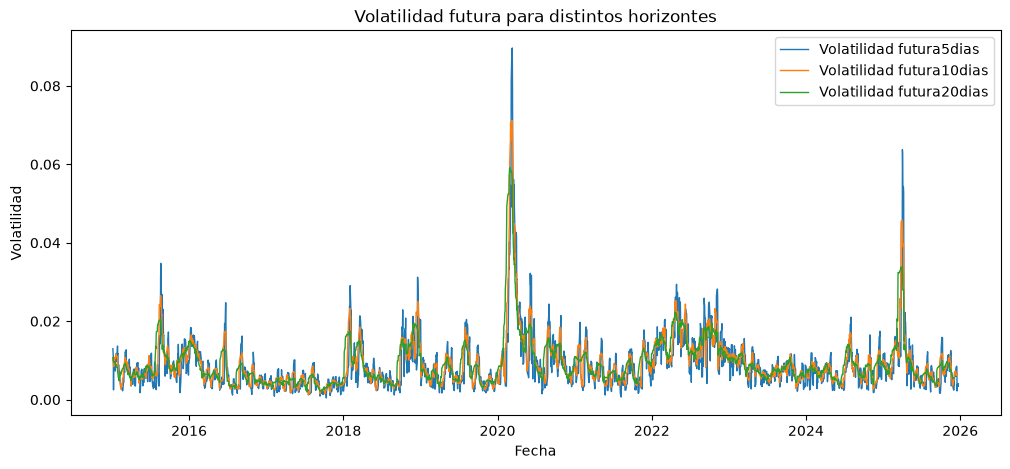

In [40]:
fig, ax= plt.subplots(figsize=(12,5))
for h in horizontes: #graficamos los horizontes usando un for
   ax.plot(
       datos.index,
       datos[f"Target_Vol_{h}"],
       label= f"Volatilidad futura{h}dias",linewidth=1 )
ax.set_title("Volatilidad futura para distintos horizontes")
ax.set_xlabel("Fecha")
ax.set_ylabel("Volatilidad")
ax.legend()
plt.show()
#permite observar visualmente que las ventanas cortas reaccionan mas rapido y las largas son mas suaves

Se observa una explosion masiva en la volatilidad que supera el valor de 0.08 a principios del año 2020 esto corresponde historicamente al choque financiero global provocado por el inicio del covid-19 donde los mercados sufrieron caidas e incertidumbres extrema.  
Tal y como lo señalan las ventanas mas cortas reaccionan con mayor velocidad y violencia ante los cambios bruscos, mientras que las ventanas mas largas producen medidas mas amortiguadas, por ello la linea azul, que es la de 5 dias, alcanza los puntos mas altos en los picos y lo mas bajos en los valles, mientras que la verde(20 dias) se mantiene mas contenida y estable

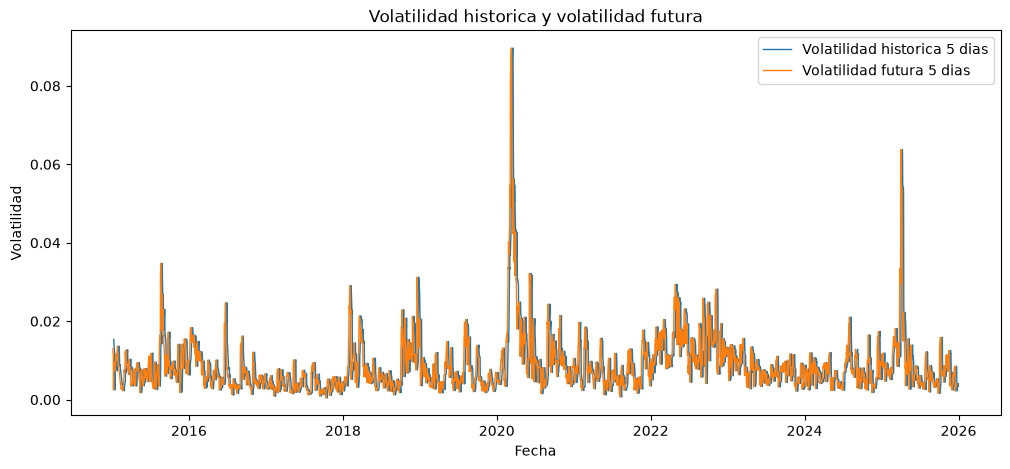

In [41]:
fig, ax=plt.subplots(figsize=(12,5))
ax.plot(datos.index, datos["Vol_5"],label="Volatilidad historica 5 dias",linewidth=1)
ax.plot(datos.index, datos["Target_Vol_5"],label="Volatilidad futura 5 dias",linewidth=1)
ax.set_title("Volatilidad historica y volatilidad futura")
ax.set_xlabel("Fecha")
ax.set_ylabel("Volatilidad")
ax.legend()
plt.show()
#se grafican simultaneamente en una misma ventana la volatilidad pasada (vol_5) y la volatilidad futura(target_vol5)
# para contrastar visualmente su comportamiento de ambas curvas a lo largo del tiempo

La curva azul resume los 5 rendimientos mas receintes hasta la fecha actual y (pasado), miesntras que la cruva naranja resume los 5 rendimientos posteriores (futuros). Ambas lienas se cruzan y siguen trayectorias muy similares porque reflejan el estado general del mercado, elevandose de forma drastica en los ultimos momentos de alta tension e incertidumbre 

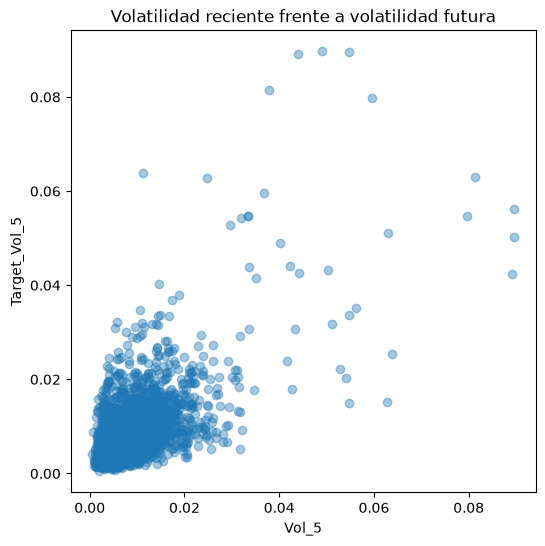

In [43]:
comparacion=(datos[["Vol_5","Target_Vol_5"]].dropna()) #extraemos las columnas y eliminamos los nulos
fig,ax= plt.subplots(figsize=(6,6))
ax.scatter(comparacion["Vol_5"], comparacion["Target_Vol_5"],alpha=0.4) #genera grafico de dispersion
ax.set_title("Volatilidad reciente frente a volatilidad futura")
ax.set_xlabel("Vol_5")
ax.set_ylabel("Target_Vol_5")
plt.show()

La inmensa mayoría de los puntos se acumulan densamente en la esquina inferior izquierda (en valores bajos de volatilidad entre 0.00 y 0.02). Esto indica que durante la mayor parte del tiempo, los mercados financieros se mantienen en un régimen de tranquilidad o volatilidad moderada tanto en el pasado reciente como en el futuro inmediato.  Los puntos que se alejan hacia arriba y hacia la derecha representan episodios inusuales o de alta turbulencia en el mercado (como crisis o momentos de gran incertidumbre, por ejemplo, el año 2020).   
Clustering: Se observa que cuando la volatilidad reciente es alta, los puntos tienden a situarse también en niveles altos de volatilidad futura, lo que refleja visualmente la persistencia de la volatilidad en el tiempo

In [44]:
#calculamos el coeficiente de correlacion lineal directo entre ambas variables
correlacion_5=(comparacion["Vol_5"].corr(comparacion["Target_Vol_5"]))
print("Correlacion:", correlacion_5)

Correlacion: 0.6335714553172058


In [47]:
correlaciones_target = (datos[columnas_target].corr() )#se observa la relacion cruzada entre los 3 horizontes, lo cual suele ser elevadas
correlaciones_target

,Target_Vol_5,Target_Vol_10,Target_Vol_20
Target_Vol_5,1.000000,0.890592,0.747407
Target_Vol_10,0.890592,1.000000,0.883366
Target_Vol_20,0.747407,0.883366,1.000000


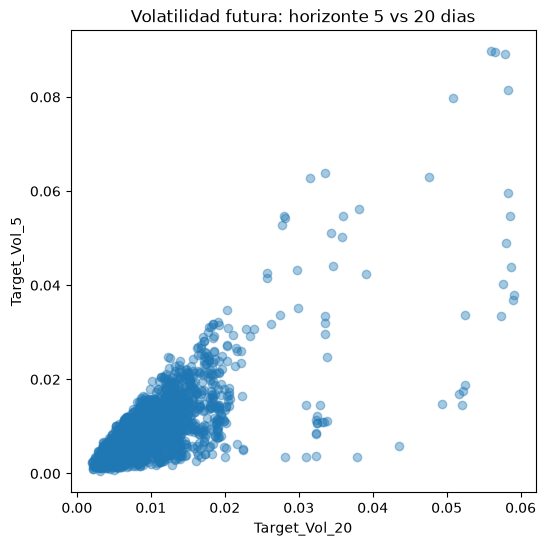

In [52]:
#diagrama de dispersion entre horizontes
fig, ax = plt.subplots(figsize=(6, 6))
muestra = datos[["Target_Vol_5", "Target_Vol_20"]].dropna()
ax.scatter(
muestra["Target_Vol_20"],
muestra["Target_Vol_5"],
alpha=0.4)
ax.set_title ( "Volatilidad futura: horizonte 5 vs 20 dias")
ax.set_xlabel("Target_Vol_20")
ax.set_ylabel("Target_Vol_5")
plt.show()

 Al igual que en la gráfica anterior, la gran mayoría de los datos se agrupan densamente en la esquina inferior izquierda (en valores bajos de volatilidad entre 0.00 y 0.02), lo que representa los periodos de estabilidad general del mercado. Se observa una clara tendencia ascendente en los puntos dispersos hacia la parte superior derecha. Esto muestra que cuando hay episodios de alta turbulencia, ambos horizontes aumentan de forma simultánea. Como se vio en la teoría de la práctica, los horizontes de 5 y 20 días comparten una enorme cantidad de observaciones futuras idénticas, lo que explica por qué presentan una correlación elevada y una relación tan estructurada. 

Las variables predictoras tiene nulos estructurales al inicio (por los rezagos moviles y medias moviles) mientras que las variables objetivo tienen nulos estructurales al final (por el horizonte futuro)


In [69]:
columnas_objetivo=["Target_Vol_5", "Target_Vol_10", "Target_Vol_20"]

In [70]:
#creamos una subtabla temporal
exploracion_5 = datos[[ "Vol_5", "Vol_20", "Mean_Abs_Return_20", "Range_HL", "Target_Vol_5"]].dropna()
  #extraemos un subconjunto de variables para analisis exploratorio

In [71]:
umbral_75= (datos["Target_Vol_5"].dropna().quantile(0.75))
print("Percentil75:",umbral_75)
#filtramos fechas donde target_vol_5 supera el umbral

Percentil75: 0.01086362341301971


In [72]:
episodios_altos=datos.loc[datos["Target_Vol_5"]>umbral_75, ["Target_Vol_5","Vol_5","Vol_20"]]
episodios_altos.head()

,Target_Vol_5,Vol_5,Vol_20
Date,,,
2015-01-05,0.012987,NaN,NaN
2015-01-06,0.011958,NaN,NaN
2015-01-21,0.011768,0.008890,NaN
2015-01-26,0.013030,0.007298,NaN
2015-01-27,0.013673,0.010642,NaN


In [73]:
#comprobamos que no se haya modficado ni alterado el calendario
for col in columnas_objetivo:
    valores = datos[col].dropna()
    assert (valores >= 0).all() 
    assert np.isfinite(valores).all()

In [74]:
#verificamos que no se haya modificado las filas
assert (datos.shape[0]== datos_features.shape[0])
assert (datos.index.equals(datos_features.index))

In [75]:
#verificamos que las clumnas originales se haya conservado
for col in datos_features.columns:
    assert col in datos.columns

In [80]:
datos= datos.drop(columns=['Objetivo_incorrecto'], errors='ignore')

In [81]:
#validamos que los 3 objetivos sean correctos
columnas_nuevas = [
   col for col in datos.columns
   if col not in datos_features.columns
]
assert columnas_nuevas == columnas_objetivo

In [82]:
print('Nuevas', columnas_nuevas)
print('objetivi', columnas_objetivo)

Nuevas ['Target_Vol_5', 'Target_Vol_10', 'Target_Vol_20']
objetivi ['Target_Vol_5', 'Target_Vol_10', 'Target_Vol_20']


In [83]:
datos_targets = datos.copy() #hacemos una copia

In [84]:
#validamos que tenga 3 columnas mas que el archivo anterior, y exportamos el df resultante de la ruta
assert (datos_targets.shape[0]== datos_features.shape[0])
assert (datos_targets.shape[1]== datos_features.shape[1] + 3)
assert datos_targets.index.equals(datos_features.index)

In [85]:
datos_targets.to_csv(archivo_targets, index=True)

In [86]:
 verificacion=pd.read_csv( archivo_targets,index_col=0,parse_dates=True)

In [88]:
#para garantizar que se guardo el archivo en el disco duro, hacemos unas pruebas para comprobar
assert(verificacion.shape==datos_targets.shape) #dimensiones
assert( verificacion.index.equals(datos_targets.index) ) #indice
assert verificacion.index.is_monotonic_increasing #orden temporal
assert verificacion.index.is_unique
for col in columnas_objetivo:
   assert col in verificacion.columns

In [91]:
for h in horizontes:
   col=f"Target_Vol_{h}"
   assert verificacion[col].isna().sum()==h #comprobamos los faltantes

In [92]:
# Definir la ruta del archivo exportado
archivo_targets = Path("data/processed/SPY_2015_2025_targets.csv")

# Verificar si existe
if archivo_targets.exists():
    print("¡El archivo targets.csv existe y está guardado correctamente!")
else:
    print("El archivo todavía no ha sido creado o la ruta es incorrecta.")

¡El archivo targets.csv existe y está guardado correctamente!
